# Proyecto: Predicción de ACV
**Integrantes:** Laura Arteaga y Faber Mongui

**Objetivo:** Predecir ACV (derrame cerebrovascular) priorizando detectar a los enfermos (Recall), porque el dataset está desbalanceado.

In [1]:
import sys
sys.path.append('.') # Para que Python encuentre la carpeta src

# Importamos nuestras funciones de la carpeta src
from src.data_loader import cargar_datos, resumen_datos
from src.preprocessing import separar_xy, armar_preprocesador, cols_numericas, cols_texto
from src.modeling import comparar_modelos, optimizar_rf
from src.evaluation import evaluar_modelo, graficar_importancias, guardar_modelo

from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

Dimensiones de la tabla: (5110, 11)

Datos vacíos (nulos):
 gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Porcentaje de ACV:
 stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64
Total de pacientes con ACV: 249


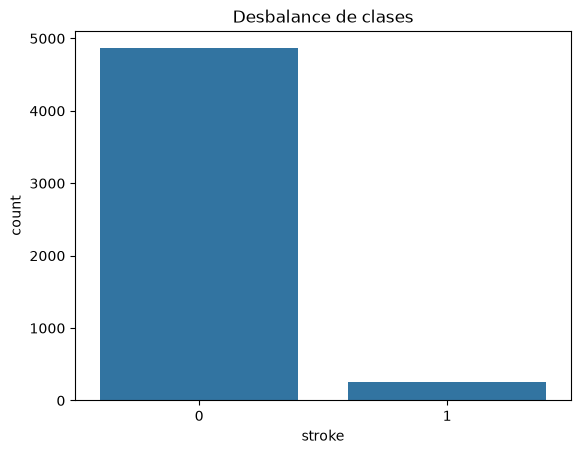

In [2]:
# 1. Cargamos los datos
df = cargar_datos("data/healthcare-dataset-stroke-data.csv")
resumen_datos(df)

# Hacemos una gráfica rápida para ver el desbalance
sns.countplot(x='stroke', data=df)
plt.title('Desbalance de clases')
plt.show()

In [3]:
# 2. Separamos X e y, y dividimos los datos (80% train, 20% test)
X, y = separar_xy(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Armamos el preprocesador
preprocesador = armar_preprocesador()
print(f"Datos de entrenamiento: {X_train.shape}")
print(f"Datos de prueba: {X_test.shape}")

Datos de entrenamiento: (4088, 10)
Datos de prueba: (1022, 10)


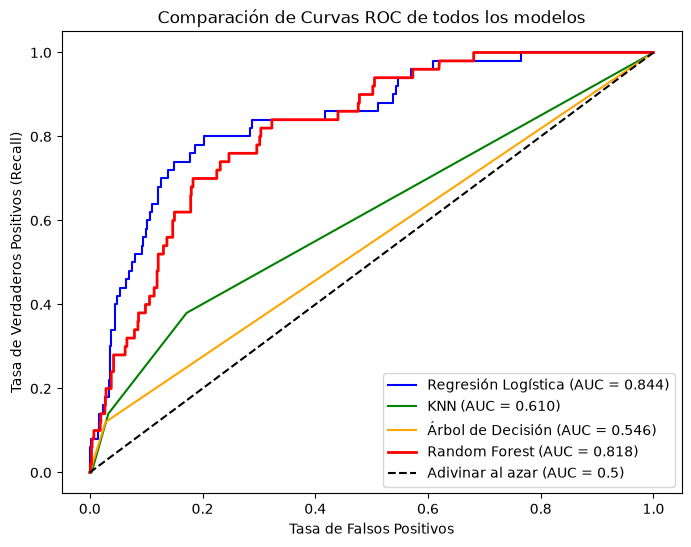

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Vamos a graficar la Curva ROC de los 4 modelos
plt.figure(figsize=(8, 6))

# 1. Regresión Logística
pipe_lr = Pipeline([('preprocesador', preprocesador), ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000))])
pipe_lr.fit(X_train, y_train)
proba_lr = pipe_lr.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, proba_lr)
auc_lr = roc_auc_score(y_test, proba_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Regresión Logística (AUC = {auc_lr:.3f})', color='blue')

# 2. KNN
pipe_knn = Pipeline([('preprocesador', preprocesador), ('modelo', KNeighborsClassifier(n_neighbors=5))])
pipe_knn.fit(X_train, y_train)
proba_knn = pipe_knn.predict_proba(X_test)[:, 1]
fpr_knn, tpr_knn, _ = roc_curve(y_test, proba_knn)
auc_knn = roc_auc_score(y_test, proba_knn)
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {auc_knn:.3f})', color='green')

# 3. Árbol de Decisión
pipe_dt = Pipeline([('preprocesador', preprocesador), ('modelo', DecisionTreeClassifier(random_state=42, class_weight='balanced'))])
pipe_dt.fit(X_train, y_train)
proba_dt = pipe_dt.predict_proba(X_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, proba_dt)
auc_dt = roc_auc_score(y_test, proba_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Árbol de Decisión (AUC = {auc_dt:.3f})', color='orange')

# 4. Random Forest (Nuestro modelo final)
proba_rf = modelo_final.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, proba_rf)
auc_rf = roc_auc_score(y_test, proba_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='red', linewidth=2)

# Línea base (adivinar al azar)
plt.plot([0, 1], [0, 1], 'k--', label='Adivinar al azar (AUC = 0.5)')

plt.title('Comparación de Curvas ROC de todos los modelos')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.legend()
plt.show()

In [4]:
# 3. Comparamos los 4 modelos
comparar_modelos(X_train, y_train, preprocesador)

Comparando modelos (F1-Score):
----------------------------------------
Regresión Logística: 0.2277
KNN: 0.0279
Árbol de Decisión: 0.1501
Random Forest: 0.1142


In [5]:
# 4. Optimizamos el Random Forest
modelo_final = optimizar_rf(X_train, y_train, preprocesador)


Mejores parámetros para Random Forest: {'modelo__max_depth': 10, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 50}
Mejor F1-Score: 0.2254


ROC-AUC: 0.8176
Umbral óptimo: 0.47

Reporte de clasificación:
              precision    recall  f1-score   support

    Sano (0)       0.98      0.85      0.91       972
     ACV (1)       0.18      0.62      0.27        50

    accuracy                           0.84      1022
   macro avg       0.58      0.73      0.59      1022
weighted avg       0.94      0.84      0.88      1022



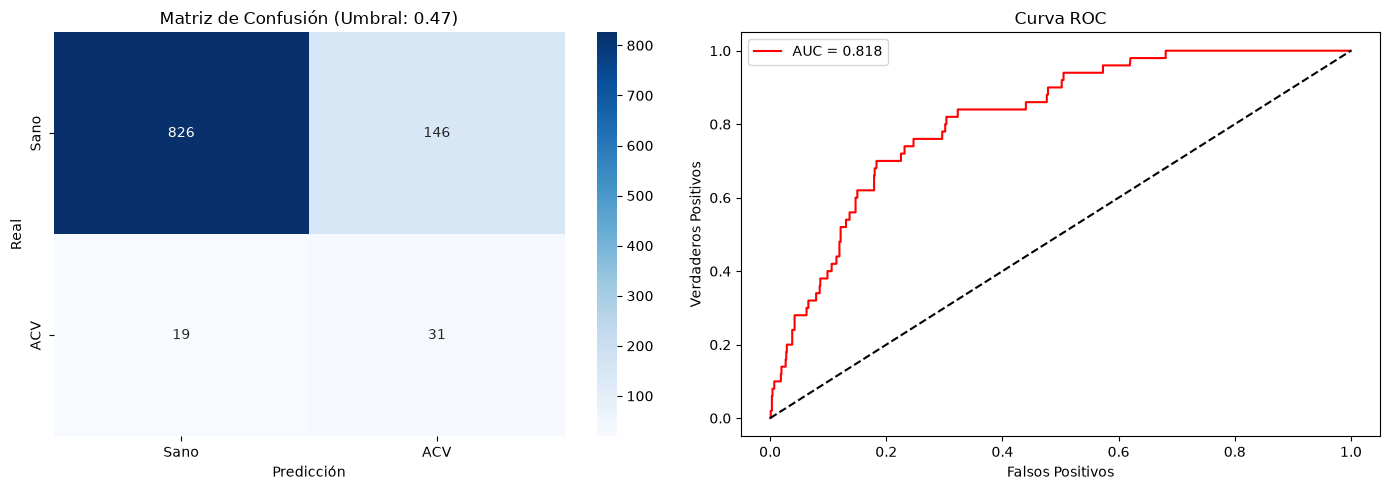

c:\Users\laura\OneDrive\Desktop\Machine Learning\Proyecto_acv\src\evaluation.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tabla, x='Importancia', y='Variable', palette='viridis')


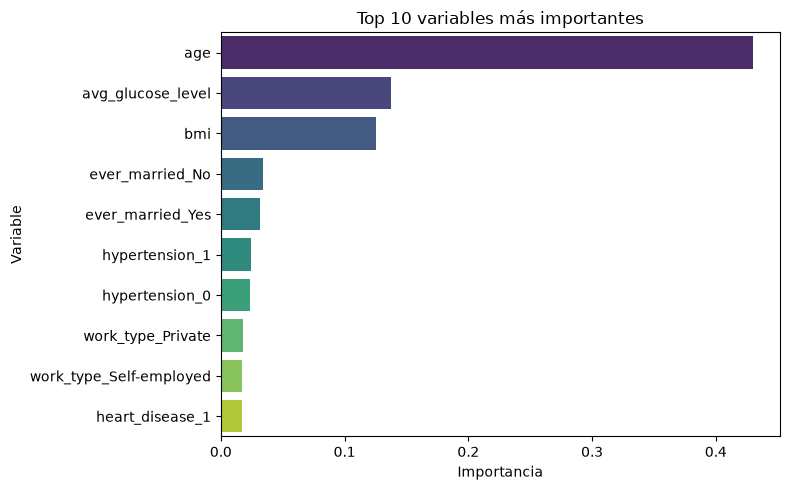


¡Modelo guardado en la carpeta outputs!


In [7]:
# 5. Evaluación final
evaluar_modelo(modelo_final, X_test, y_test)
graficar_importancias(modelo_final, cols_numericas, cols_texto)
guardar_modelo(modelo_final)